Tema 2

Setul de date Fashion

In [ ]:
import os
import gzip
import numpy as np
import cv2
from PIL import Image
import random
from skimage.feature import hog
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, log_loss
from sklearn.preprocessing import StandardScaler

import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset, Dataset

In [ ]:
def load_mnist(path, kind='train'):
    labels_path = os.path.join(path, '%s-labels-idx1-ubyte.gz' % kind)
    images_path = os.path.join(path, '%s-images-idx3-ubyte.gz' % kind)

    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8, offset=8)

    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8, offset=16).reshape(len(labels), 784)

    return images, labels

In [ ]:
X_train, y_train = load_mnist('./', kind='train')
X_test, y_test = load_mnist('./', kind='t10k')

In [ ]:
print(len(X_train))
print(len(y_train))
print(len(X_test))
print(len(y_test))

60000
60000
10000
10000


In [ ]:
print(X_train[0].shape)
print(X_train.shape)

(784,)
(60000, 784)


In [ ]:
unique_classes = list(set([cls for cls in y_train]))

print(f"Numărul claselor: {len(unique_classes)}")

Numărul claselor: 10


In [ ]:
labels_description = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

1. Extragerea de atribute

Atribute HOG

In [ ]:
def extract_hog_features(image):
    features = hog(image, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=False)

    return features

In [ ]:
def hog_extraction(images):
    hog_features = []
    for img in tqdm(images, desc="Extracting HOG Features"):
        img = img.reshape(28, 28)
        features = extract_hog_features(img)
        hog_features.append(features)

    return hog_features

In [ ]:
hog_features_train = hog_extraction(X_train)
hog_features_test = hog_extraction(X_test)

Extracting HOG Features: 100%|██████████| 10000/10000 [00:02<00:00, 4471.94it/s]


In [ ]:
print("HOG Features Train Size:", len(hog_features_train))
print("HOG Features Test Size:", len(hog_features_test))

HOG Features Train Size: 60000
HOG Features Test Size: 10000


Atribute ORB

In [ ]:
def extract_orb_features_and_images(image):
    image = cv2.resize(image, (128, 128))
    orb = cv2.ORB_create()
    keypoints, descriptors = orb.detectAndCompute(image, None)

    copy_image = np.copy(image)

    # generare imagini pentru vizualizarea punctelor cheie
    keypoints_image = cv2.drawKeypoints(copy_image, keypoints, None, color = (0, 255, 0))
    orb_image = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

    return keypoints, descriptors, orb_image, keypoints_image

In [ ]:
def orb_extraction(images):
    orb_features = []
    orb_keypoints = []
    skipped_indices = []

    for i, img in tqdm(enumerate(images), desc="Extracting ORB Features"):
        img = img.reshape(28, 28)

        keypoints, descriptors, orb_image, _ = extract_orb_features_and_images(img)

        if descriptors is not None:
            orb_features.append(descriptors)
            orb_keypoints.append(keypoints)
        else:
            skipped_indices.append(i)


    return orb_features, orb_keypoints, skipped_indices

In [ ]:
orb_features_train, orb_keypoints_train, skipped_indices_train = orb_extraction(X_train)
orb_features_test, orb_keypoints_test, skipped_indices_test = orb_extraction(X_test)

Extracting ORB Features: 60000it [01:20, 748.65it/s]
Extracting ORB Features: 10000it [00:12, 823.72it/s]


In [ ]:
print("ORB Features Train Size:", len(orb_features_train))
print("ORB Features Test Size:", len(orb_features_test))

ORB Features Train Size: 56490
ORB Features Test Size: 9408


I. MLP pe atributele extrase

HOG

In [ ]:
hog_max = 0

for features in hog_features_train:
    if len(features) > hog_max:
        hog_max = len(features)

print(hog_max)

144


In [ ]:
hog_max = 0

for features in hog_features_test:
    if len(features) > hog_max:
        hog_max = len(features)

print(hog_max)

144


In [ ]:
hog_selector = SelectPercentile(score_func=f_classif, percentile=40)

X_train_hog_reduced = hog_selector.fit_transform(hog_features_train, y_train)
X_test_hog_reduced = hog_selector.transform(hog_features_test)

In [ ]:
hog_max = 0

for features in X_train_hog_reduced:
    if len(features) > hog_max:
        hog_max = len(features)

print("Numarul de atribute HOG maxim dupa aplicarea Select Percentile este", hog_max)

Numarul de atribute HOG maxim dupa aplicarea Select Percentile este 58


In [ ]:
# standardizarea datelor
scaler = StandardScaler()
X_train_hog = scaler.fit_transform(X_train_hog_reduced)
X_test_hog = scaler.transform(X_test_hog_reduced)

# tranformare valori => media = 0 si deviatia standard = 1
# functiile de activare sunt sensibile la scale mari ale intrarilor
# imbunatatire acuratete

In [ ]:
# modelul MLP pentru atributele HOG
mlp_hog = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=20,
    random_state=42,
    verbose=True
)

start_time = time.time()

train_accuracy_curve_hog = []
test_accuracy_curve_hog = []
train_loss_curve_hog = []
test_loss_curve_hog = []

for epoch in range(mlp_hog.max_iter):
    mlp_hog.partial_fit(X_train_hog, y_train, classes=np.unique(y_train))

    train_accuracy_curve_hog.append(accuracy_score(y_train, mlp_hog.predict(X_train_hog)))
    test_accuracy_curve_hog.append(accuracy_score(y_test, mlp_hog.predict(X_test_hog)))

    train_loss_curve_hog.append(mlp_hog.loss_)
    test_loss_curve_hog.append(log_loss(y_test, mlp_hog.predict_proba(X_test_hog)))

    print(f"Epoch {epoch + 1}/{mlp_hog.max_iter}, Train Loss: {train_loss_curve_hog[-1]:.4f}, Test Loss: {test_loss_curve_hog[-1]:.4f}, Train Acc: {train_accuracy_curve_hog[-1] * 100:.2f}%, Test Acc: {test_accuracy_curve_hog[-1] * 100:.2f}%")

end_time = time.time()

Iteration 1, loss = 0.65842958
Epoch 1/20, Train Loss: 0.6584, Test Loss: 0.5717, Train Acc: 79.50%, Test Acc: 78.29%
Iteration 1, loss = 0.52078980
Epoch 2/20, Train Loss: 0.5208, Test Loss: 0.5295, Train Acc: 81.63%, Test Acc: 79.65%
Iteration 1, loss = 0.48996730
Epoch 3/20, Train Loss: 0.4900, Test Loss: 0.5139, Train Acc: 82.45%, Test Acc: 80.35%
Iteration 1, loss = 0.47139625
Epoch 4/20, Train Loss: 0.4714, Test Loss: 0.5070, Train Acc: 82.98%, Test Acc: 80.40%
Iteration 1, loss = 0.45757280
Epoch 5/20, Train Loss: 0.4576, Test Loss: 0.5018, Train Acc: 83.39%, Test Acc: 80.54%
Iteration 1, loss = 0.44670822
Epoch 6/20, Train Loss: 0.4467, Test Loss: 0.5013, Train Acc: 83.65%, Test Acc: 80.45%
Iteration 1, loss = 0.43728531
Epoch 7/20, Train Loss: 0.4373, Test Loss: 0.4996, Train Acc: 83.92%, Test Acc: 80.55%
Iteration 1, loss = 0.42929112
Epoch 8/20, Train Loss: 0.4293, Test Loss: 0.4994, Train Acc: 84.14%, Test Acc: 80.75%
Iteration 1, loss = 0.42185180
Epoch 9/20, Train Loss: 0

In [ ]:
training_time = end_time - start_time
print(f"Timpul de antrenare: {training_time:.2f} secunde")

Timpul de antrenare: 34.17 secunde


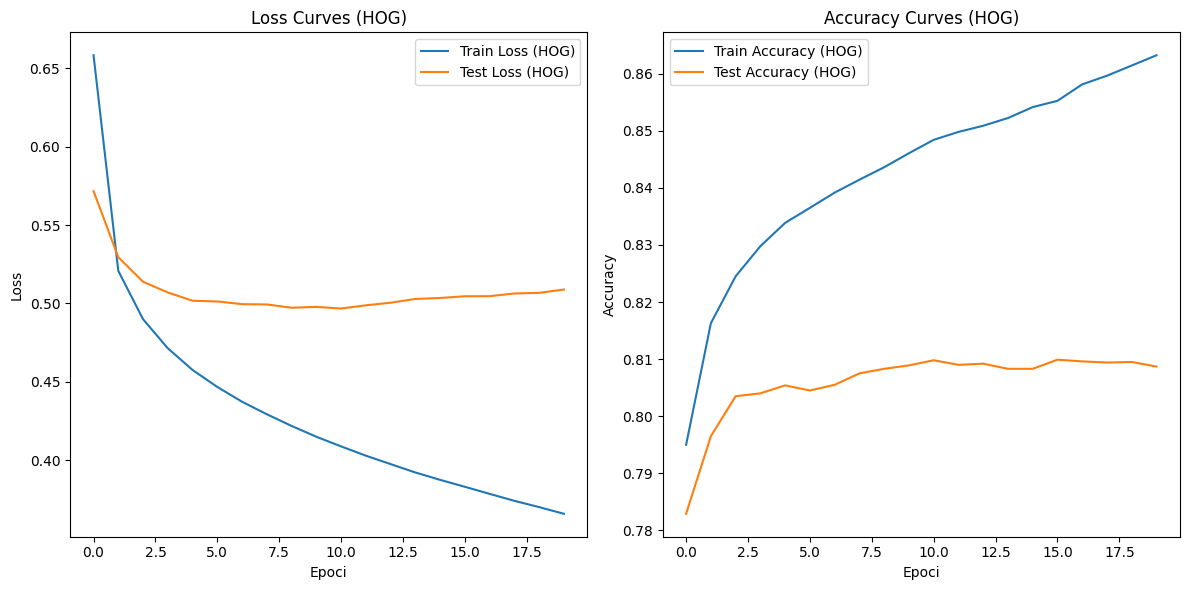

In [ ]:
plt.figure(figsize=(12, 6))

# curba de loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_curve_hog, label='Train Loss (HOG)')
plt.plot(test_loss_curve_hog, label='Test Loss (HOG)')
plt.title('Loss Curves (HOG)')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# curba de accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracy_curve_hog, label='Train Accuracy (HOG)')
plt.plot(test_accuracy_curve_hog, label='Test Accuracy (HOG)')
plt.title('Accuracy Curves (HOG)')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
y_pred_hog = mlp_hog.predict(X_test_hog)

# raport de clasificare
report_hog = classification_report(
    y_test,
    y_pred_hog,
    target_names=[labels_description[label] for label in sorted(labels_description.keys())]
)

print("Raport de clasificare pentru modelul MLP cu atribute HOG")
print(report_hog)

Raport de clasificare pentru modelul MLP cu atribute HOG
              precision    recall  f1-score   support

 T-shirt/top       0.80      0.75      0.77      1000
     Trouser       0.98      0.93      0.95      1000
    Pullover       0.71      0.64      0.68      1000
       Dress       0.83      0.82      0.83      1000
        Coat       0.67      0.68      0.67      1000
      Sandal       0.93      0.90      0.91      1000
       Shirt       0.50      0.58      0.54      1000
     Sneaker       0.85      0.92      0.89      1000
         Bag       0.95      0.95      0.95      1000
  Ankle boot       0.95      0.91      0.93      1000

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.81     10000
weighted avg       0.81      0.81      0.81     10000



ORB

In [ ]:
orb_max = 0

for features in orb_features_train:
    if len(features) > orb_max:
        orb_max = len(features)

print(orb_max)

244


In [ ]:
orb_min = 0

for features in orb_features_train:
    if len(features) < orb_min:
        orb_min = len(features)

print(orb_min)

0


In [ ]:
orb_max = 0

for features in orb_features_test:
    if len(features) > orb_max:
        orb_max = len(features)

print(orb_max)

240


In [ ]:
orb_min = 0

for features in orb_features_test:
    if len(features) < orb_min:
        orb_min = len(features)

print(orb_min)

0


In [ ]:
y_train_orb = y_train
y_train_orb = np.delete(y_train_orb, skipped_indices_train)

In [ ]:
y_test_orb = y_test
y_test_orb = np.delete(y_test_orb, skipped_indices_test)

In [ ]:
X_train_orb = orb_features_train
X_test_orb = orb_features_test

In [ ]:
max_len = max(
    max(len(descriptors) for descriptors in orb_features_train),
    max(len(descriptors) for descriptors in orb_features_test)
)

In [ ]:
X_train_orb = [
    np.pad(descriptors, ((0, max_len - len(descriptors)), (0, 0)), 'constant')
    for descriptors in orb_features_train
]

In [ ]:
X_test_orb = [
    np.pad(descriptors, ((0, max_len - len(descriptors)), (0, 0)), 'constant')
    for descriptors in orb_features_test
]

In [ ]:
orb_max = 0

for features in X_train_orb:
    if len(features) > orb_max:
        orb_max = len(features)

print("Numarul maxim de atribute ORB este", orb_max)

Numarul maxim de atribute ORB este 244


In [ ]:
reshaped_orb_features_train = np.array([descriptors.flatten() for descriptors in X_train_orb])
reshaped_orb_features_test = np.array([descriptors.flatten() for descriptors in X_test_orb])

In [ ]:
print(reshaped_orb_features_train.shape)

(56490, 7808)


In [ ]:
selector_orb = SelectPercentile(score_func=f_classif, percentile=26)

X_train_orb_reduced = selector_orb.fit_transform(reshaped_orb_features_train, y_train_orb)
X_test_orb_reduced = selector_orb.transform(reshaped_orb_features_test)

In [ ]:
# standardizare a datelor
scaler_orb = StandardScaler()
X_train_orb = scaler_orb.fit_transform(X_train_orb_reduced)
X_test_orb = scaler_orb.transform(X_test_orb_reduced)

# tranformare valori => media = 0 si deviatia standard = 1
# functiile de activare sunt sensibile la scale mari ale intrarilor
# imbunatatire acuratete

In [ ]:
# modelul MLP pentru ORB
mlp_orb = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=20,
    random_state=42,
    verbose=True
)

start_time = time.time()

train_accuracy_curve_orb = []
test_accuracy_curve_orb = []
train_loss_curve_orb = []
test_loss_curve_orb = []

for epoch in range(mlp_orb.max_iter):
    mlp_orb.partial_fit(X_train_orb, y_train_orb, classes=np.unique(y_train_orb))

    train_accuracy_curve_orb.append(accuracy_score(y_train_orb, mlp_orb.predict(X_train_orb)))
    test_accuracy_curve_orb.append(accuracy_score(y_test_orb, mlp_orb.predict(X_test_orb)))

    train_loss_curve_orb.append(mlp_orb.loss_)
    test_loss_curve_orb.append(log_loss(y_test_orb, mlp_orb.predict_proba(X_test_orb)))

    print(f"Epoch {epoch + 1}/{mlp_orb.max_iter}, Train Loss: {train_loss_curve_orb[-1]:.4f}, Test Loss: {test_loss_curve_orb[-1]:.4f}, Train Acc: {train_accuracy_curve_orb[-1] * 100:.2f}%, Test Acc: {test_accuracy_curve_orb[-1] * 100:.2f}%")

end_time = time.time()

Iteration 1, loss = 1.65303493
Epoch 1/20, Train Loss: 1.6530, Test Loss: 1.5001, Train Acc: 48.39%, Test Acc: 45.61%
Iteration 1, loss = 1.43319696
Epoch 2/20, Train Loss: 1.4332, Test Loss: 1.4654, Train Acc: 50.66%, Test Acc: 46.78%
Iteration 1, loss = 1.34610280
Epoch 3/20, Train Loss: 1.3461, Test Loss: 1.4536, Train Acc: 52.59%, Test Acc: 47.49%
Iteration 1, loss = 1.27983495
Epoch 4/20, Train Loss: 1.2798, Test Loss: 1.4905, Train Acc: 53.01%, Test Acc: 47.10%
Iteration 1, loss = 1.22323024
Epoch 5/20, Train Loss: 1.2232, Test Loss: 1.5150, Train Acc: 54.86%, Test Acc: 47.35%
Iteration 1, loss = 1.16665607
Epoch 6/20, Train Loss: 1.1667, Test Loss: 1.6188, Train Acc: 54.77%, Test Acc: 47.28%
Iteration 1, loss = 1.11778162
Epoch 7/20, Train Loss: 1.1178, Test Loss: 1.6472, Train Acc: 56.03%, Test Acc: 47.06%
Iteration 1, loss = 1.07255892
Epoch 8/20, Train Loss: 1.0726, Test Loss: 1.7453, Train Acc: 55.89%, Test Acc: 46.24%
Iteration 1, loss = 1.03519673
Epoch 9/20, Train Loss: 1

In [ ]:
training_time = end_time - start_time
print(f"Timpul de antrenare: {training_time:.2f} secunde")

Timpul de antrenare: 193.60 secunde


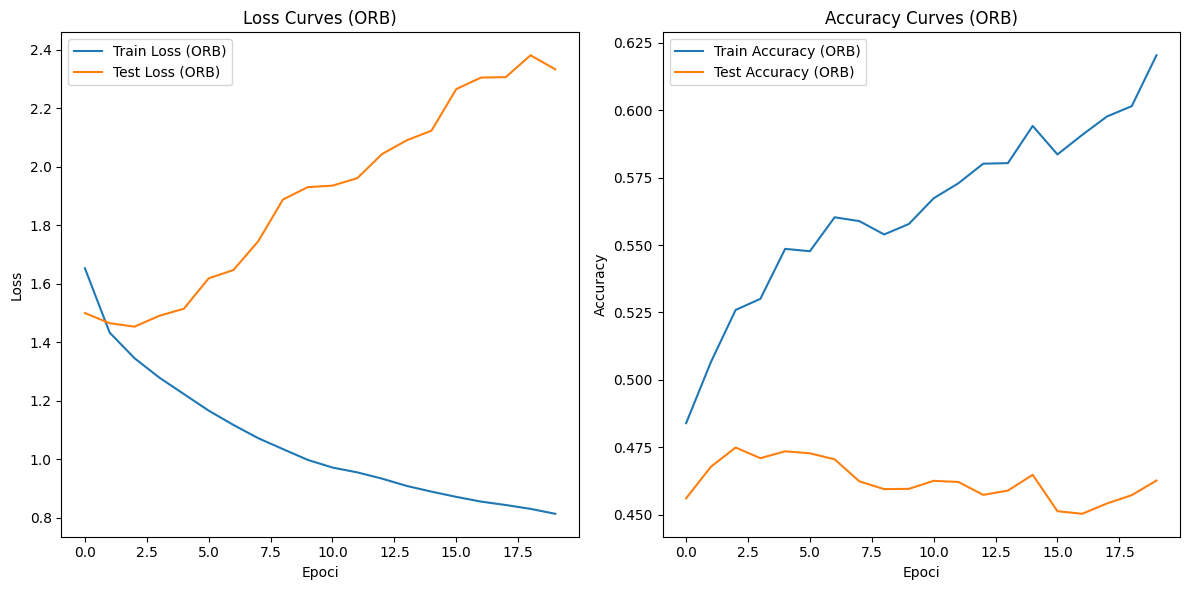

In [ ]:
plt.figure(figsize=(12, 6))

# curba de loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_curve_orb, label='Train Loss (ORB)')
plt.plot(test_loss_curve_orb, label='Test Loss (ORB)')
plt.title('Loss Curves (ORB)')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# curba de accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracy_curve_orb, label='Train Accuracy (ORB)')
plt.plot(test_accuracy_curve_orb, label='Test Accuracy (ORB)')
plt.title('Accuracy Curves (ORB)')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
y_pred_orb = mlp_orb.predict(X_test_orb)

# raport de clasificare
report_orb = classification_report(
    y_test_orb,
    y_pred_orb,
    target_names=[labels_description[label] for label in sorted(labels_description.keys())]
)

print("\nRaport de clasificare pentru modelul MLP cu atribute ORB")
print(report_orb)


Raport de clasificare pentru modelul MLP cu atribute ORB
              precision    recall  f1-score   support

 T-shirt/top       0.31      0.44      0.37       918
     Trouser       0.56      0.50      0.53       985
    Pullover       0.30      0.37      0.33       911
       Dress       0.43      0.48      0.45       955
        Coat       0.27      0.29      0.28       876
      Sandal       0.69      0.60      0.64       999
       Shirt       0.23      0.16      0.19       873
     Sneaker       0.75      0.64      0.69      1000
         Bag       0.42      0.36      0.39       894
  Ankle boot       0.68      0.71      0.69       997

    accuracy                           0.46      9408
   macro avg       0.46      0.45      0.46      9408
weighted avg       0.47      0.46      0.46      9408



II. Arhitectura de tip MLP direct peste imagini

In [ ]:
# liniarizare
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

In [ ]:
X_train_flat.shape

(60000, 784)

In [ ]:
# standardizarea datelor
scaler_flat = StandardScaler()
X_train_img = scaler_flat.fit_transform(X_train_flat)
X_test_img = scaler_flat.transform(X_test_flat)

In [ ]:
# model MLP
class MLP(nn.Module):
    def __init__(self, num_classes=10):
        super(MLP, self).__init__()
        in_size = 1 * 28 * 28

        self.fc1 = nn.Linear(in_size, 256)
        self.fc2 = nn.Linear(256, 256)
        self.fc3 = nn.Linear(256, num_classes)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = x.view(-1, 1 * 28 * 28)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [ ]:
num_classes = len(np.unique(y_train))
model = MLP(num_classes=num_classes)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# optimizator și funcție de pierdere
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
X_train_tensor = torch.tensor(X_train_img, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_img, dtype=torch.float32).to(device)

y_train_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

In [ ]:
num_epochs = 20
batch_size = 64

train_loader = DataLoader(torch.utils.data.TensorDataset(X_train_tensor, y_train_tensor), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(torch.utils.data.TensorDataset(X_test_tensor, y_test_tensor), batch_size=batch_size, shuffle=False)

In [ ]:
train_accuracy_img = []
test_accuracy_img = []
train_loss_img = []
test_loss_img = []

start_time = time.time()

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    train_loss_img.append(running_loss / len(train_loader.dataset))
    train_accuracy_img.append(100.0 * correct / total)

    # evaluare pe setul de test
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in test_loader:
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    test_loss_img.append(test_loss / len(test_loader.dataset))
    test_accuracy_img.append(100.0 * correct / total)

    print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_loss_img[-1]:.4f}, Test Loss: {test_loss_img[-1]:.4f}, Train Acc: {train_accuracy_img[-1]:.2f}%, Test Acc: {test_accuracy_img[-1]:.2f}%")

end_time = time.time()

Epoch 1/20, Train Loss: 0.4374, Test Loss: 0.3839, Train Acc: 84.16%, Test Acc: 85.84%
Epoch 2/20, Train Loss: 0.3225, Test Loss: 0.3519, Train Acc: 88.04%, Test Acc: 86.71%
Epoch 3/20, Train Loss: 0.2847, Test Loss: 0.3617, Train Acc: 89.42%, Test Acc: 87.22%
Epoch 4/20, Train Loss: 0.2585, Test Loss: 0.3393, Train Acc: 90.35%, Test Acc: 87.79%
Epoch 5/20, Train Loss: 0.2362, Test Loss: 0.3719, Train Acc: 91.06%, Test Acc: 86.91%
Epoch 6/20, Train Loss: 0.2158, Test Loss: 0.3700, Train Acc: 91.87%, Test Acc: 88.03%
Epoch 7/20, Train Loss: 0.1960, Test Loss: 0.3669, Train Acc: 92.61%, Test Acc: 88.22%
Epoch 8/20, Train Loss: 0.1840, Test Loss: 0.3619, Train Acc: 93.07%, Test Acc: 88.57%
Epoch 9/20, Train Loss: 0.1663, Test Loss: 0.3782, Train Acc: 93.66%, Test Acc: 88.33%
Epoch 10/20, Train Loss: 0.1562, Test Loss: 0.3897, Train Acc: 94.17%, Test Acc: 88.13%
Epoch 11/20, Train Loss: 0.1435, Test Loss: 0.4093, Train Acc: 94.62%, Test Acc: 88.79%
Epoch 12/20, Train Loss: 0.1329, Test Los

In [ ]:
training_time = end_time - start_time
print(f"Timpul total de antrenare pentru MLP (direct peste imagini): {training_time:.2f} secunde")

Timpul total de antrenare pentru MLP (direct peste imagini): 45.30 secunde


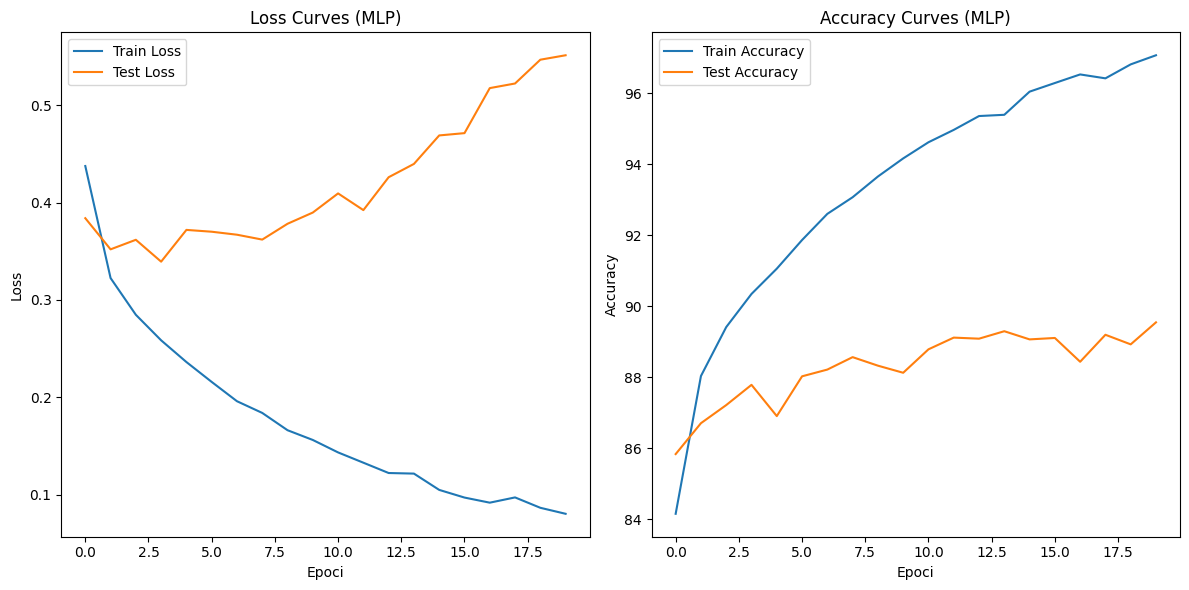

In [ ]:
plt.figure(figsize=(12, 6))

# loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_img, label='Train Loss')
plt.plot(test_loss_img, label='Test Loss')
plt.title('Loss Curves (MLP)')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracy_img, label='Train Accuracy')
plt.plot(test_accuracy_img, label='Test Accuracy')
plt.title('Accuracy Curves (MLP)')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# raport de clasificare pentru modelul MLP (direct peste imagini)
y_test_pred_img = []
model.eval()
with torch.no_grad():
    for inputs, _ in test_loader:
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        y_test_pred_img.extend(predicted.cpu().numpy())

print("Raport de clasificare pentru modelul MLP direct peste imagini")
print(classification_report(y_test, y_test_pred_img, target_names=[labels_description[label] for label in sorted(labels_description.keys())]))

Raport de clasificare pentru modelul MLP direct peste imagini
              precision    recall  f1-score   support

 T-shirt/top       0.81      0.86      0.84      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.80      0.85      0.83      1000
       Dress       0.91      0.89      0.90      1000
        Coat       0.84      0.83      0.84      1000
      Sandal       0.97      0.97      0.97      1000
       Shirt       0.75      0.69      0.72      1000
     Sneaker       0.95      0.95      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.95      0.96      0.95      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



III. Arhitectura de tip convolutional

In [ ]:
# definire augmentari
augmentations = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize((0.5), (0.5,))
])

no_augmentations = transforms.Compose([
    # transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [ ]:
class ImageDataset(torch.utils.data.Dataset):
    def __init__(self, dataset, labels, transform=None):
        self.dataset = dataset
        self.transform = transform
        self.labels = labels

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image = self.dataset[idx]
        label = self.labels[idx]

        image = image.reshape(28, 28)

        image = Image.fromarray(image.astype(np.uint8))

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
# crearea seturilor de date cu și fără augmentări
train_dataset_no_aug = ImageDataset(X_train, y_train, transform=no_augmentations)
train_dataset_aug = ImageDataset(X_train, y_train, transform=augmentations)
test_dataset = ImageDataset(X_test, y_test, transform=no_augmentations)

train_loader_no_aug = DataLoader(train_dataset_no_aug, batch_size=64, shuffle=True)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
print(len(np.unique(y_train)))
print(len(np.unique(y_test)))

10
10


In [ ]:
# arhitectura CNN
class DeepConvNet(nn.Module):
    def __init__(self, num_classes=10):
        super(DeepConvNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=7, stride=2, padding=3)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        self.bn3 = nn.BatchNorm2d(64)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        x = self.conv3(x)
        x = self.bn3(x)
        x = self.relu(x)

        x = self.global_pool(x)
        # x = torch.flatten(x, 1)
        # x = x.view(-1, x.size(0))

        x = x.view(x.size(0), -1)

        x = self.dropout(x)
        x = self.fc(x)

        return x

In [ ]:
def train_model(model, train_loader, test_loader, num_epochs=20):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    test_losses = []
    train_accuracies = []
    test_accuracies = []

    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        train_losses.append(train_loss / len(train_loader.dataset))
        train_accuracies.append(100.0 * correct / total)

        model.eval()
        test_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                test_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

        test_losses.append(test_loss / len(test_loader.dataset))
        test_accuracies.append(100.0 * correct / total)

        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_losses[-1]:.4f}, Test Loss: {test_losses[-1]:.4f}, Train Acc: {train_accuracies[-1]:.2f}%, Test Acc: {test_accuracies[-1]:.2f}%")

    end_time = time.time()
    training_time = end_time - start_time

    print(f"\n\nTimpul total de antrenare: {training_time:.2f} secunde")

    return train_losses, test_losses, train_accuracies, test_accuracies


In [ ]:
model = DeepConvNet(num_classes=10)
print("Antrenare model fara augmentari!\n")
train_losses, test_losses, train_accuracies, test_accuracies = train_model(model, train_loader_no_aug, test_loader)

Antrenare model fara augmentari!

Epoch 1/20, Train Loss: 0.7861, Test Loss: 0.4744, Train Acc: 74.03%, Test Acc: 83.19%
Epoch 2/20, Train Loss: 0.5078, Test Loss: 0.4043, Train Acc: 82.01%, Test Acc: 85.08%
Epoch 3/20, Train Loss: 0.4568, Test Loss: 0.3751, Train Acc: 83.92%, Test Acc: 86.32%
Epoch 4/20, Train Loss: 0.4257, Test Loss: 0.3671, Train Acc: 84.97%, Test Acc: 86.53%
Epoch 5/20, Train Loss: 0.4064, Test Loss: 0.3538, Train Acc: 85.90%, Test Acc: 86.99%
Epoch 6/20, Train Loss: 0.3877, Test Loss: 0.3424, Train Acc: 86.31%, Test Acc: 87.75%
Epoch 7/20, Train Loss: 0.3748, Test Loss: 0.3409, Train Acc: 86.77%, Test Acc: 87.85%
Epoch 8/20, Train Loss: 0.3650, Test Loss: 0.3206, Train Acc: 87.06%, Test Acc: 88.28%
Epoch 9/20, Train Loss: 0.3527, Test Loss: 0.3226, Train Acc: 87.60%, Test Acc: 88.46%
Epoch 10/20, Train Loss: 0.3465, Test Loss: 0.3088, Train Acc: 87.74%, Test Acc: 88.54%
Epoch 11/20, Train Loss: 0.3401, Test Loss: 0.3078, Train Acc: 88.05%, Test Acc: 88.91%
Epoch 1

In [ ]:
model_augmented = DeepConvNet(num_classes=10)
print("Antrenare model cu augmentari!\n")
aug_train_losses, aug_test_losses, aug_train_accuracies, aug_test_accuracies = train_model(model_augmented, train_loader_aug, test_loader)

Antrenare model cu augmentari!

Epoch 1/20, Train Loss: 1.4610, Test Loss: 0.9005, Train Acc: 46.37%, Test Acc: 68.30%
Epoch 2/20, Train Loss: 1.1994, Test Loss: 0.7718, Train Acc: 56.58%, Test Acc: 73.01%
Epoch 3/20, Train Loss: 1.1428, Test Loss: 0.6884, Train Acc: 58.74%, Test Acc: 74.88%
Epoch 4/20, Train Loss: 1.1013, Test Loss: 0.6690, Train Acc: 60.23%, Test Acc: 75.34%
Epoch 5/20, Train Loss: 1.0822, Test Loss: 0.6475, Train Acc: 60.95%, Test Acc: 76.08%
Epoch 6/20, Train Loss: 1.0494, Test Loss: 0.6212, Train Acc: 62.19%, Test Acc: 78.03%
Epoch 7/20, Train Loss: 1.0366, Test Loss: 0.6375, Train Acc: 62.79%, Test Acc: 77.57%
Epoch 8/20, Train Loss: 1.0210, Test Loss: 0.5869, Train Acc: 63.23%, Test Acc: 79.23%
Epoch 9/20, Train Loss: 1.0129, Test Loss: 0.5895, Train Acc: 63.45%, Test Acc: 78.95%
Epoch 10/20, Train Loss: 0.9969, Test Loss: 0.5718, Train Acc: 64.23%, Test Acc: 79.47%
Epoch 11/20, Train Loss: 0.9929, Test Loss: 0.5763, Train Acc: 64.23%, Test Acc: 79.21%
Epoch 12/

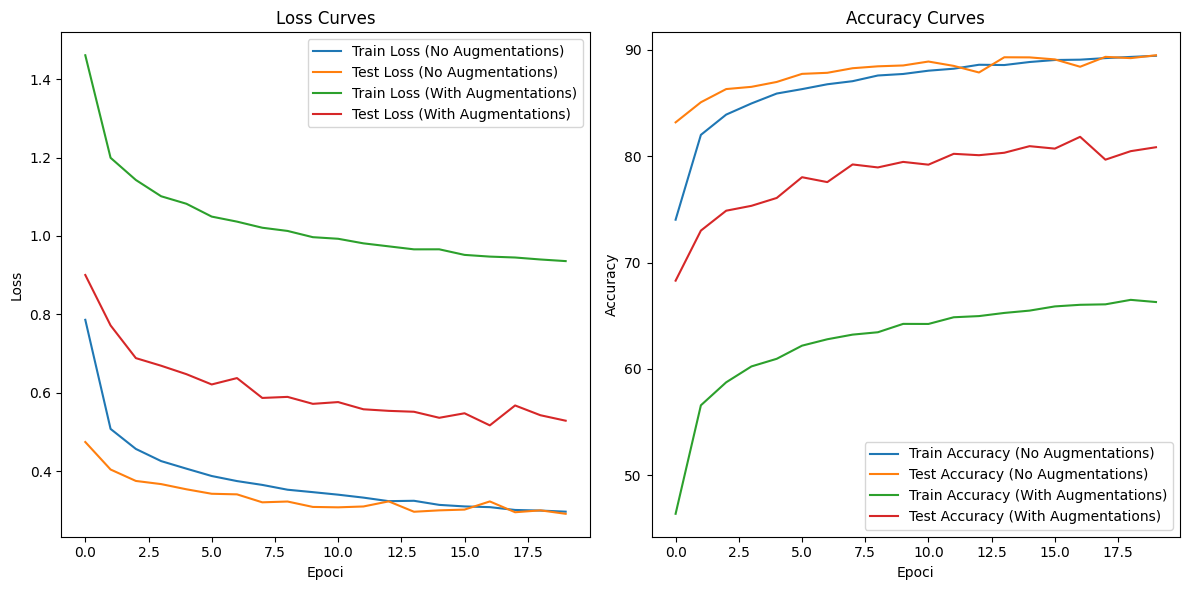

In [ ]:
plt.figure(figsize=(12, 6))

# Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss (No Augmentations)')
plt.plot(test_losses, label='Test Loss (No Augmentations)')
plt.plot(aug_train_losses, label='Train Loss (With Augmentations)')
plt.plot(aug_test_losses, label='Test Loss (With Augmentations)')
plt.title('Loss Curves')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy (No Augmentations)')
plt.plot(test_accuracies, label='Test Accuracy (No Augmentations)')
plt.plot(aug_train_accuracies, label='Train Accuracy (With Augmentations)')
plt.plot(aug_test_accuracies, label='Test Accuracy (With Augmentations)')
plt.title('Accuracy Curves')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# raport de clasificare pentru modelul fără augmentări
model.eval()
all_targets_no_aug = []
all_predictions_no_aug = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        all_targets_no_aug.extend(targets.cpu().numpy())
        all_predictions_no_aug.extend(predicted.cpu().numpy())

print("Raport de clasificare pentru modelul fără augmentări")
print(classification_report(all_targets_no_aug, all_predictions_no_aug, zero_division=0))

Raport de clasificare pentru modelul fără augmentări
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1000
           1       1.00      0.96      0.98      1000
           2       0.85      0.86      0.85      1000
           3       0.88      0.91      0.89      1000
           4       0.84      0.83      0.83      1000
           5       0.98      0.96      0.97      1000
           6       0.70      0.70      0.70      1000
           7       0.94      0.97      0.95      1000
           8       0.97      0.97      0.97      1000
           9       0.96      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.89      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [ ]:
# raport de clasificare pentru modelul cu augmentări
model_augmented.eval()
all_targets_aug = []
all_predictions_aug = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model_augmented(inputs)
        _, predicted = outputs.max(1)
        all_targets_aug.extend(targets.cpu().numpy())
        all_predictions_aug.extend(predicted.cpu().numpy())

print("Raport de clasificare pentru modelul cu augmentări")
print(classification_report(all_targets_aug, all_predictions_aug, zero_division=0))

Raport de clasificare pentru modelul cu augmentări
              precision    recall  f1-score   support

           0       0.78      0.77      0.77      1000
           1       0.99      0.95      0.97      1000
           2       0.72      0.77      0.74      1000
           3       0.68      0.91      0.78      1000
           4       0.64      0.77      0.70      1000
           5       0.97      0.90      0.93      1000
           6       0.63      0.28      0.39      1000
           7       0.79      0.98      0.87      1000
           8       0.94      0.93      0.94      1000
           9       0.98      0.82      0.89      1000

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.80     10000
weighted avg       0.81      0.81      0.80     10000

